# Issue #6: Association Rule Mining for Charging Behaviour

**Inputs (Issue #5, repository root):** `association_onehot.csv`, `association_baskets.csv`, `association_category_definitions.csv`  
**Outputs (repository root):** `arm_frequent_itemsets.csv`, `arm_rules_all.csv`, `arm_rules_filtered.csv` (every rule with its keep/remove reason), `arm_rules_final.csv`, `arm_rules_headline.csv`, `arm_rules_by_regime.csv`, `arm_figures/`, `arm_summary_i6.md`

**Measures**
- **support(A → C)** = share of sessions containing every item of A and C
- **confidence(A → C)** = support(A ∪ C) / support(A) = P(C | A)
- **lift(A → C)** = confidence / support(C). 1 = independent; 1.5 = C is 50% more likely when A holds
- **leverage** = support(A ∪ C) − support(A)·support(C) (extra sessions explained, as a share of all sessions); **conviction** = (1 − support(C)) / (1 − confidence)

In [1]:
from pathlib import Path
def find_root(marker):
    """Repository root = the folder holding `marker` (this folder or its parent)."""
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found in this folder or its parent")
import sys
ROOT = find_root("acn_clean_sessions.csv")
sys.path.insert(0, str(ROOT))

import json, time
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FIG = ROOT / "arm_figures"; FIG.mkdir(exist_ok=True)
onehot = pd.read_csv(ROOT / "association_onehot.csv").set_index("transaction_id")
baskets = pd.read_csv(ROOT / "association_baskets.csv", usecols=["transaction_id", "regime"]).set_index("transaction_id")
defs = pd.read_csv(ROOT / "association_category_definitions.csv")
regime = baskets["regime"].reindex(onehot.index)
assert regime.notna().all() and onehot.isin([0, 1]).all().all()
ITEMS = list(onehot.columns)
ATTR = {c: c.split("=")[0] for c in ITEMS}
X = onehot.values.astype(bool)
N = len(X)
print(f"{N:,} transactions x {len(ITEMS)} items; regimes: {regime.value_counts().to_dict()}")

31,387 transactions x 36 items; regimes: {'R3 paid': 14802, 'R1 free': 8361, 'R2 free, 14 kWh default': 4735, 'R4 COVID period': 3489}


## 1. Choice of approach

| Option | Decision | Reason |
|---|---|---|
| **Apriori / FP-Growth** (frequent itemsets → rules) | **used** | Standard for categorical "basket" data; gives support, confidence and lift for every rule; results are exact, not sampled. FP-Growth (via `mlxtend`, if installed) and the built-in Apriori below give identical itemsets. Apriori is used when `mlxtend` is missing, and the two are cross-checked when both are available |
| Eclat | not used | Same itemsets as Apriori; no advantage at this size (31k transactions, 36 items) |
| Sequential pattern mining | not used | Sessions are independent events; order within a session is not the question |
| Rules on numeric data (quantitative ARM) | not used | Issue #5 already discretised the features into meaningful categories |

**Mining scope.** All sessions together, with `regime` as an item, so a rule can be conditioned on a regime. Then each regime separately (section 6), because a pattern that holds only under free charging can disappear when sessions from all regimes are pooled together.

**Rule shape.** Consequents have one item (*"sessions with A tend to have C"*), which keeps rules readable and avoids counting the same pattern several times. Antecedents have at most 3 items (itemsets up to 4 items).

In [2]:
MINE_SUPPORT = 0.01   # mining floor; the filtering threshold below is stricter, the floor lets the sensitivity table go lower
MAX_LEN = 4

def apriori(X, columns, min_support, max_len):
    """columns = item names in the column order of X; candidates are generated in sorted item order."""
    n = len(X); sup = {}
    cols = {i: X[:, k] for k, i in enumerate(columns)}
    level = []
    for i in sorted(columns):
        s = cols[i].mean()
        if s >= min_support:
            sup[(i,)] = s; level.append((i,))
    k = 1
    while level and k < max_len:
        k += 1
        prev = set(level); cand = set()
        level_sorted = sorted(level)
        for a in range(len(level_sorted)):
            for b in range(a + 1, len(level_sorted)):
                p, q = level_sorted[a], level_sorted[b]
                if p[:-1] != q[:-1]:
                    break
                c = p + (q[-1],)
                if len({ATTR[x] for x in c}) < len(c):          # two items of the same attribute never co-occur
                    continue
                if all(tuple(s) in prev for s in combinations(c, k - 1)):
                    cand.add(c)
        level = []
        for c in sorted(cand):
            m = cols[c[0]].copy()
            for x in c[1:]:
                m &= cols[x]
            s = m.sum() / n
            if s >= min_support:
                sup[c] = s; level.append(c)
    return sup

t0 = time.time()
support = apriori(X, ITEMS, MINE_SUPPORT, MAX_LEN)
engine = "built-in Apriori"
try:
    from mlxtend.frequent_patterns import fpgrowth
    fp = fpgrowth(onehot.astype(bool), min_support=MINE_SUPPORT, use_colnames=True, max_len=MAX_LEN)
    fp_sup = {tuple(sorted(s)): v for s, v in zip(fp["itemsets"], fp["support"])}
    same = set(fp_sup) == set(support) and all(abs(fp_sup[k] - support[k]) < 1e-9 for k in support)
    engine = ("mlxtend FP-Growth, cross-checked against the built-in Apriori: identical itemsets" if same else
              "built-in Apriori (mlxtend FP-Growth gave different itemsets; check the mlxtend version)")
except ImportError:
    pass
# sanity check: item and pair supports computed directly from the one-hot table
for k in list(support)[:50] + [k for k in support if len(k) == 2][:50]:
    assert abs(onehot[list(k)].all(axis=1).mean() - support[k]) < 1e-12, k
fi = pd.DataFrame([{"itemset": " + ".join(k), "size": len(k), "support": v, "sessions": round(v * N)} for k, v in support.items()])
fi = fi.sort_values(["size", "support"], ascending=[True, False]).reset_index(drop=True)
fi.to_csv(ROOT / "arm_frequent_itemsets.csv", index=False)
print(f"Engine: {engine} | {len(fi):,} frequent itemsets at support >= {MINE_SUPPORT:.0%} ({time.time() - t0:.1f}s)")
display(fi.groupby("size").agg(itemsets=("itemset", "size"), max_support=("support", "max")).style.format({"max_support": "{:.1%}"}))
display(fi[fi["size"] >= 2].sort_values("support", ascending=False).head(10).style.format({"support": "{:.1%}"}))

Engine: built-in Apriori | 9,725 frequent itemsets at support >= 1% (2.2s)


,itemsets,max_support
size,,
1,36,93.8%
2,485,79.0%
3,2637,46.9%
4,6567,37.3%


,itemset,size,support,sessions
36,day_type=weekday + overnight=no,2,79.0%,24811
37,overnight=no + station=other,2,52.0%,16309
38,overnight=no + user=claimed,2,49.5%,15525
39,day_type=weekday + station=other,2,49.1%,15421
521,day_type=weekday + overnight=no + station=other,3,46.9%,14725
40,request=not_met + user=claimed,2,45.5%,14289
41,overnight=no + regime=R3_paid,2,44.9%,14087
42,day_type=weekday + user=claimed,2,44.4%,13951
43,overnight=no + user=unclaimed,2,44.3%,13915
522,overnight=no + request=not_met + user=claimed,3,43.3%,13576


## 2. Generate rules and compute support, confidence, lift

In [3]:
rows = []
for itemset, s in support.items():
    if len(itemset) < 2:
        continue
    for c in itemset:
        a = tuple(x for x in itemset if x != c)
        sa, sc = support[a], support[(c,)]
        conf = s / sa
        rows.append({"antecedent": " + ".join(a), "consequent": c, "n_antecedent": len(a), "support": s, "sessions": round(s * N),
                     "antecedent_support": sa, "consequent_support": sc, "confidence": conf, "lift": conf / sc,
                     "leverage": s - sa * sc, "conviction": (1 - sc) / (1 - conf) if conf < 1 else np.inf})
rules = pd.DataFrame(rows)
rules["rule"] = "{" + rules["antecedent"] + "} -> {" + rules["consequent"] + "}"
conf_of = {(r.antecedent, r.consequent): r.confidence for r in rules.itertuples()}
rules.to_csv(ROOT / "arm_rules_all.csv", index=False)
print(f"{len(rules):,} candidate rules from {int((fi['size'] >= 2).sum()):,} itemsets of size >= 2")
display(rules[["support", "confidence", "lift", "leverage"]].describe().T.style.format("{:.3f}"))

35,149 candidate rules from 9,689 itemsets of size >= 2


,count,mean,std,min,25%,50%,75%,max
support,35149.000,0.037,0.041,0.010,0.015,0.023,0.043,0.790
confidence,35149.000,0.484,0.266,0.013,0.271,0.427,0.674,1.000
lift,35149.000,1.270,0.698,0.151,0.932,1.113,1.472,16.121
leverage,35149.000,0.004,0.014,-0.150,-0.002,0.003,0.008,0.218


## 3. Thresholds

| Threshold | Value | Reason |
|---|---|---|
| min support | **2%** (≈ 630 sessions) | Large enough for stable estimates and practical relevance; R2, the shortest regime, still contributes patterns at this level |
| min confidence | **0.60** | The consequent holds in most sessions matching the antecedent, so the rule is a usable description |
| min lift | **1.20** | At least 20% more likely than chance; below that, a high confidence usually just reflects a very common consequent (e.g. weekday, 84% of sessions) |
| min improvement | **0.05** | A longer rule is kept only if its confidence beats every shorter version by ≥ 5 points (redundancy rule, section 4) |

The sensitivity table shows how many rules pass at nearby values, so the choice can be judged.

,conf >= 50%,conf >= 60%,conf >= 70%,conf >= 80%
rules with lift >= 1.2,,,,
support >= 1%,7898,5813,3774,2394
support >= 2%,4815,3540,2331,1498
support >= 3%,3378,2477,1633,1051
support >= 5%,1858,1345,917,616


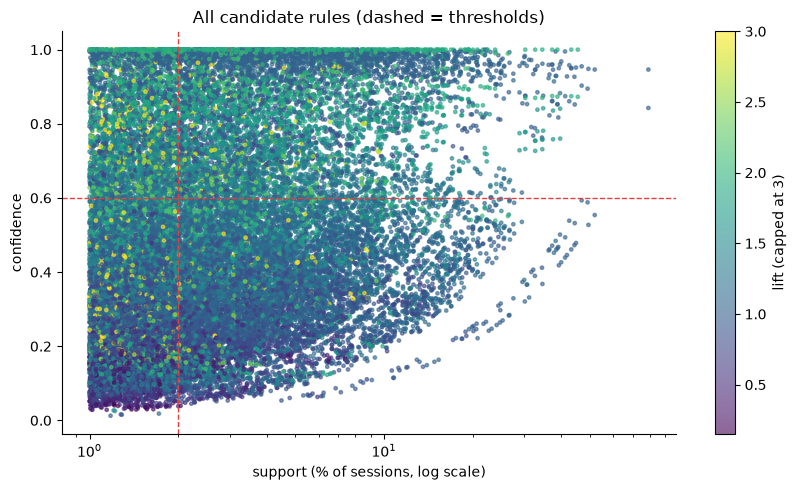

In [4]:
MIN_SUPPORT, MIN_CONF, MIN_LIFT, MIN_IMPROVEMENT = 0.02, 0.60, 1.20, 0.05
sens = pd.DataFrame({f"conf >= {c:.0%}": [int(((rules.support >= s) & (rules.confidence >= c) & (rules.lift >= MIN_LIFT)).sum())
                                          for s in [0.01, 0.02, 0.03, 0.05]] for c in [0.5, 0.6, 0.7, 0.8]},
                    index=[f"support >= {s:.0%}" for s in [0.01, 0.02, 0.03, 0.05]])
sens.index.name = f"rules with lift >= {MIN_LIFT}"
sens.to_csv(ROOT / "arm_threshold_sensitivity.csv")
display(sens)

fig, ax = plt.subplots(figsize=(8.5, 5))
sc = ax.scatter(rules.support * 100, rules.confidence, c=rules.lift.clip(upper=3), cmap="viridis", s=6, alpha=0.6)
ax.axvline(MIN_SUPPORT * 100, color="#e53e3e", ls="--", lw=1); ax.axhline(MIN_CONF, color="#e53e3e", ls="--", lw=1)
ax.set_xscale("log"); ax.set(xlabel="support (% of sessions, log scale)", ylabel="confidence", title="All candidate rules (dashed = thresholds)")
fig.colorbar(sc, label="lift (capped at 3)"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "A01_support_confidence_lift.png", dpi=150); plt.show()

## 4. Remove weak, redundant and meaningless rules

Each rule gets the **first** reason that applies:

| Reason | Rule removed when … | Why |
|---|---|---|
| `weak` | support, confidence or lift is below the thresholds | Not frequent, not reliable or not better than chance |
| `negative association` | lift < 1 | Describes items that avoid each other; reported separately, not as a behaviour rule |
| `by construction` | it links `request` with `user` | A request exists only for claimed sessions, so the rule is true by definition |
| `time, not behaviour` | the consequent is a `regime` | "This session happened in 2019" is not a behaviour; regimes are kept as context in antecedents |
| `near-arithmetic` | two of {stay, energy, charging_share, power} predict a third, **or** `overnight` appears together with `arrival` or `stay` | Energy ≈ power × charging time and charging share = charging time / stay; staying overnight follows from arrival time + stay length |
| `weak among app users` | the consequent is a `request` outcome and the lift measured **among app users only** is below the threshold | A request exists only for app users; without this, the rule mostly restates which sessions are claimed |
| `redundant` | a shorter antecedent gives the same consequent with confidence within 0.05 | The extra condition adds nothing |
| `mirror` | the same item pair already appears in the other direction with higher confidence | One rule per pair is enough for the final set |

Rules that pass but come from operator rules are kept with the label **`policy-driven`**: every rule whose consequent is `user` (claim rates were set by pricing policy: 1% claimed in R1, 84% in R3), and every rule that combines `user` with `regime`, `energy`, `power` or `charging_share` (the 14 kWh default for unclaimed sessions in R2 and the 30-minute stop under paid charging). They are reported, but separately from driver behaviour.

In [5]:
ARITH = {"stay", "energy", "charging_share", "power"}
TIME_DERIVED = {"arrival", "stay"}          # overnight = arrival time + stay length crosses midnight
col_all = {c: X[:, k] for k, c in enumerate(ITEMS)}
claimed = col_all["user=claimed"]
def lift_among_claimed(antecedent, consequent):
    a = claimed.copy()
    for x in antecedent.split(" + "):
        a &= col_all[x]
    if a.sum() == 0:
        return np.nan
    return ((a & col_all[consequent]).sum() / a.sum()) / (col_all[consequent][claimed].mean())
def arithmetic(attrs_a, attr_c):
    if attr_c in ARITH and len(attrs_a & ARITH) >= 2:
        return True
    both = attrs_a | {attr_c}
    return "overnight" in both and bool(both & TIME_DERIVED)
def reasons(r):
    a = r.antecedent.split(" + "); c = r.consequent
    attrs_a = {ATTR[x] for x in a}; attr_c = ATTR[c]
    if r.lift < 1:
        return "negative association"
    if r.support < MIN_SUPPORT or r.confidence < MIN_CONF or r.lift < MIN_LIFT:
        return "weak"
    if ({"request", "user"} <= attrs_a | {attr_c}):
        return "by construction"
    if attr_c == "regime":
        return "time, not behaviour"
    if arithmetic(attrs_a, attr_c):
        return "near-arithmetic"
    if attr_c == "request" and not (lift_among_claimed(r.antecedent, c) >= MIN_LIFT):
        return "weak among app users"
    if len(a) > 1:
        for k in range(1, len(a)):
            for sub in combinations(a, k):
                key = (" + ".join(sub), c)
                if key in conf_of and r.confidence - conf_of[key] < MIN_IMPROVEMENT:
                    return "redundant"
    return "kept"

rules["status"] = [reasons(r) for r in rules.itertuples()]
# mirror pairs: single-item rules A->C and C->A; keep the direction with higher confidence
single = rules[(rules.status == "kept") & (rules.n_antecedent == 1)].copy()
single["pair"] = [tuple(sorted([a, c])) for a, c in zip(single.antecedent, single.consequent)]
drop = single.sort_values("confidence", ascending=False).duplicated("pair", keep="first")
rules.loc[single.index[drop.values], "status"] = "mirror"

def policy(r):
    items = set(r.antecedent.split(" + ")) | {r.consequent}
    attrs = {ATTR[x] for x in items}
    return bool(ATTR[r.consequent] == "user" or ("user" in attrs and attrs & {"regime", "energy", "power", "charging_share"}))
rules["policy_driven"] = [policy(r) for r in rules.itertuples()]
order = ["kept", "redundant", "mirror", "weak among app users", "near-arithmetic", "time, not behaviour", "by construction", "weak", "negative association"]
funnel = rules["status"].value_counts().reindex(order).fillna(0).astype(int).to_frame("rules")
funnel.loc["kept (policy-driven)"] = int(((rules.status == "kept") & rules.policy_driven).sum())
funnel.loc["kept (driver behaviour)"] = int(((rules.status == "kept") & ~rules.policy_driven).sum())
rules.to_csv(ROOT / "arm_rules_filtered.csv", index=False)
display(funnel)

,rules
status,
kept,295
redundant,1351
mirror,0
weak among app users,258
near-arithmetic,595
"time, not behaviour",517
by construction,524
weak,20025
negative association,11584


## 5. Final set of meaningful rules

In [6]:
PHRASE = {
    "arrival=night": "arrive at night (00-06)", "arrival=morning": "arrive in the morning (06-10)", "arrival=midday": "arrive at midday (10-14)",
    "arrival=afternoon": "arrive in the afternoon (14-18)", "arrival=evening": "arrive in the evening (18-24)",
    "day_type=weekday": "on a weekday", "day_type=weekend": "at the weekend", "day_type=closure": "on a campus-closure day",
    "stay=under_2h": "stay under 2 h", "stay=2-6h": "stay 2-6 h", "stay=6-10h": "stay 6-10 h", "stay=over_10h": "stay over 10 h",
    "energy=under_2kWh": "take under 2 kWh", "energy=2-7kWh": "take 2-7 kWh", "energy=7-13kWh": "take 7-13 kWh",
    "energy=13-14kWh_default": "take 13-14 kWh (default allowance)", "energy=14-21kWh": "take 14-21 kWh", "energy=over_21kWh": "take over 21 kWh",
    "charging_share=mostly_idle": "are mostly idle (charging < 40% of the stay)", "charging_share=partly_idle": "are partly idle (charging 40-80%)",
    "charging_share=mostly_charging": "are charging most of the stay (>= 80%)",
    "power=low": "charge below 3 kW", "power=medium": "charge at 3-5 kW", "power=high": "charge at 5 kW or more",
    "user=claimed": "are app users", "user=unclaimed": "are not claimed in the app",
    "request=met": "get >= 90% of the energy requested", "request=not_met": "get < 90% of the energy requested",
    "overnight=yes": "stay overnight", "overnight=no": "leave the same day",
    "station=busy": "use one of the busiest chargers", "station=other": "use a less busy charger",
    "regime=R1_free": "under free charging (R1)", "regime=R2_free_default": "under free charging with the 14 kWh default (R2)",
    "regime=R3_paid": "under paid charging (R3)", "regime=R4_covid": "in the COVID/recovery period (R4)",
}
missing = set(ITEMS) - set(PHRASE)
assert not missing, missing
CONTEXT = {"day_type", "regime"}
def sentence(r):
    a = r.antecedent.split(" + ")
    verbs = [PHRASE[x] for x in a if ATTR[x] not in CONTEXT]
    ctx = [PHRASE[x] for x in a if ATTR[x] in CONTEXT]
    subj = "Sessions" + (" that " + " and ".join(verbs) if verbs else "") + ((", " if verbs else " ") + ", ".join(ctx) if ctx else "")
    cons = ("are " if ATTR[r.consequent] in CONTEXT else "") + PHRASE[r.consequent]
    return f"{subj}: {r.confidence:.0%} {cons} ({r.lift:.2f}x the overall rate of {r.consequent_support:.0%})."
THEME = {"arrival": "timing", "day_type": "timing", "stay": "stay & idle time", "charging_share": "stay & idle time",
         "overnight": "stay & idle time", "energy": "energy & power", "power": "energy & power", "user": "users & requests",
         "request": "users & requests", "station": "charger use", "regime": "regime"}
final = rules[(rules.status == "kept")].copy()
final["theme"] = final["consequent"].map(lambda c: THEME[ATTR[c]])
final["description"] = [sentence(r) for r in final.itertuples()]
final["lift_among_app_users"] = [lift_among_claimed(r.antecedent, r.consequent) if ATTR[r.consequent] == "request" else np.nan
                                 for r in final.itertuples()]
final = final.sort_values(["policy_driven", "lift"], ascending=[True, False])
cols = ["rule", "support", "confidence", "lift", "leverage", "conviction", "sessions", "theme", "policy_driven", "lift_among_app_users", "description"]
final[cols].to_csv(ROOT / "arm_rules_final.csv", index=False)
behaviour = final[~final.policy_driven]
display(Markdown(f"**{len(behaviour)} driver-behaviour rules** and {int(final.policy_driven.sum())} policy-driven rules. Top 20 by lift:"))
display(behaviour[cols[:-1]].head(20).style.format({"support": "{:.1%}", "confidence": "{:.0%}", "lift": "{:.2f}", "leverage": "{:.3f}", "conviction": "{:.2f}"}))
display(Markdown("\n".join(f"- {d}" for d in behaviour["description"].head(12))))
if final.policy_driven.any():
    display(Markdown("**Policy-driven rules (operator rules, not driver choice)**"))
    display(final[final.policy_driven][["rule", "support", "confidence", "lift"]].head(10).style.format({"support": "{:.1%}", "confidence": "{:.0%}", "lift": "{:.2f}"}))

**165 driver-behaviour rules** and 130 policy-driven rules. Top 20 by lift:

,rule,support,confidence,lift,leverage,conviction,sessions,theme,policy_driven,lift_among_app_users
7379,{energy=over_21kWh + regime=R3_paid} -> {power=high},2.7%,73%,2.91,0.017,2.77,836,energy & power,False,nan
1296,{arrival=afternoon + energy=under_2kWh} -> {stay=under_2h},2.3%,76%,2.83,0.015,3.06,715,stay & idle time,False,nan
1485,{arrival=afternoon + regime=R4_covid} -> {stay=under_2h},2.0%,72%,2.67,0.013,2.60,632,stay & idle time,False,nan
1779,{arrival=evening + energy=2-7kWh} -> {stay=under_2h},3.4%,71%,2.64,0.021,2.50,1060,stay & idle time,False,nan
7391,{energy=over_21kWh + station=other} -> {power=high},2.3%,64%,2.57,0.014,2.11,734,energy & power,False,nan
6114,{day_type=weekend + energy=2-7kWh} -> {stay=under_2h},3.3%,69%,2.56,0.020,2.34,1043,stay & idle time,False,nan
10048,{arrival=afternoon + energy=2-7kWh + station=busy} -> {stay=under_2h},2.1%,69%,2.56,0.013,2.33,665,stay & idle time,False,nan
1791,{arrival=evening + energy=7-13kWh} -> {power=high},2.4%,62%,2.48,0.014,1.99,749,energy & power,False,nan
8101,{regime=R2_free_default + stay=under_2h} -> {power=high},2.5%,61%,2.43,0.015,1.92,781,energy & power,False,nan
1593,{arrival=evening + charging_share=mostly_charging} -> {stay=under_2h},5.4%,64%,2.38,0.032,2.03,1708,stay & idle time,False,nan


- Sessions that take over 21 kWh, under paid charging (R3): 73% charge at 5 kW or more (2.91x the overall rate of 25%).
- Sessions that arrive in the afternoon (14-18) and take under 2 kWh: 76% stay under 2 h (2.83x the overall rate of 27%).
- Sessions that arrive in the afternoon (14-18), in the COVID/recovery period (R4): 72% stay under 2 h (2.67x the overall rate of 27%).
- Sessions that arrive in the evening (18-24) and take 2-7 kWh: 71% stay under 2 h (2.64x the overall rate of 27%).
- Sessions that take over 21 kWh and use a less busy charger: 64% charge at 5 kW or more (2.57x the overall rate of 25%).
- Sessions that take 2-7 kWh, at the weekend: 69% stay under 2 h (2.56x the overall rate of 27%).
- Sessions that arrive in the afternoon (14-18) and take 2-7 kWh and use one of the busiest chargers: 69% stay under 2 h (2.56x the overall rate of 27%).
- Sessions that arrive in the evening (18-24) and take 7-13 kWh: 62% charge at 5 kW or more (2.48x the overall rate of 25%).
- Sessions that stay under 2 h, under free charging with the 14 kWh default (R2): 61% charge at 5 kW or more (2.43x the overall rate of 25%).
- Sessions that arrive in the evening (18-24) and are charging most of the stay (>= 80%): 64% stay under 2 h (2.38x the overall rate of 27%).
- Sessions that get < 90% of the energy requested and use one of the busiest chargers and stay 6-10 h: 71% are mostly idle (charging < 40% of the stay) (2.38x the overall rate of 30%).
- Sessions that arrive in the afternoon (14-18) and take 2-7 kWh: 64% stay under 2 h (2.37x the overall rate of 27%).

**Policy-driven rules (operator rules, not driver choice)**

,rule,support,confidence,lift
7600,{regime=R3_paid + user=unclaimed} -> {energy=under_2kWh},7.2%,95%,6.09
21958,{charging_share=mostly_charging + regime=R3_paid + user=unclaimed} -> {power=low},3.4%,100%,2.42
12219,{arrival=evening + power=high + user=unclaimed} -> {stay=under_2h},2.6%,61%,2.28
8287,{regime=R3_paid + user=unclaimed} -> {power=low},7.1%,94%,2.27
24417,{station=busy + stay=6-10h + user=claimed} -> {charging_share=mostly_idle},4.8%,66%,2.22
18483,{arrival=morning + energy=under_2kWh + user=unclaimed} -> {power=low},3.5%,91%,2.21
849,{regime=R1_free} -> {user=unclaimed},26.4%,99%,2.07
18089,{energy=2-7kWh + stay=6-10h + user=unclaimed} -> {arrival=morning},3.4%,85%,2.04
11178,{arrival=evening + stay=under_2h + user=unclaimed} -> {charging_share=mostly_charging},3.7%,83%,2.02
8631,{regime=R2_free_default + stay=under_2h} -> {user=unclaimed},3.9%,96%,2.01


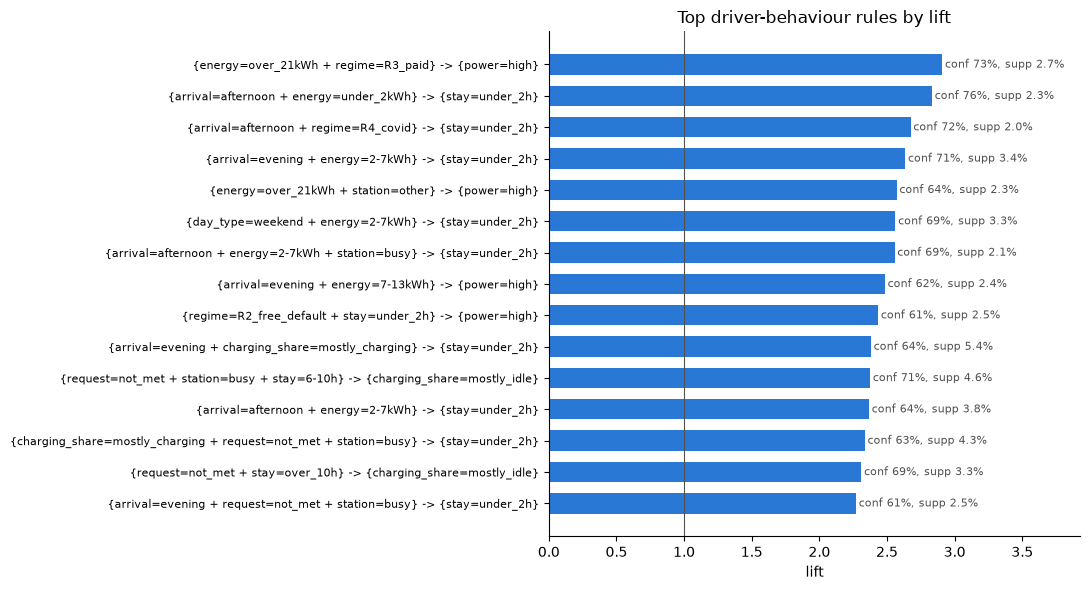

In [7]:
top = behaviour.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top["rule"], top["lift"], color="#2a78d6", height=0.65)
for i, (l, c, s) in enumerate(zip(top.lift, top.confidence, top.support)):
    ax.text(l + 0.02, i, f"conf {c:.0%}, supp {s:.1%}", va="center", fontsize=8, color="#52514e")
ax.axvline(1, color="#52514e", lw=0.8)
ax.set(xlabel="lift", title="Top driver-behaviour rules by lift"); ax.tick_params(axis="y", labelsize=8)
ax.set_xlim(0, top.lift.max() * 1.35); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "A02_top_rules.png", dpi=150); plt.show()

## 6. Regime check

Pricing changed behaviour (Issues #10, #16), so every final rule without a regime in its antecedent is re-measured **inside each regime**. A rule is called *stable* when its lift is at least 1.1 in every regime that has ≥ 100 sessions matching the antecedent. Then each regime is mined on its own (min support 5% of that regime's sessions, same other thresholds) to find patterns that pooling hides.

In [8]:
REG = list(regime.value_counts().sort_index().index)
reg_masks = {g: (regime == g).values for g in REG}
col = {c: X[:, k] for k, c in enumerate(ITEMS)}
def measure(antecedent, consequent, mask):
    a = np.ones(mask.sum(), bool)
    for x in antecedent.split(" + "):
        a &= col[x][mask]
    c = col[consequent][mask]
    na = a.sum()
    if na == 0 or c.mean() == 0:
        return na, np.nan, np.nan
    conf = (a & c).sum() / na
    return na, conf, conf / c.mean()
stab_rows = []
for r in behaviour.itertuples():
    if "regime=" in r.antecedent:
        continue
    row = {"rule": r.rule, "lift_all": r.lift}
    lifts = []
    for g in REG:
        na, conf, lift = measure(r.antecedent, r.consequent, reg_masks[g])
        row[f"lift {g}"] = lift; row[f"conf {g}"] = conf
        if na >= 100 and not np.isnan(lift):
            lifts.append(lift)
    row["stable"] = bool(lifts) and min(lifts) >= 1.1
    stab_rows.append(row)
stability = pd.DataFrame(stab_rows)
n_stable = int(stability["stable"].sum()) if len(stability) else 0
display(Markdown(f"**{n_stable} of {len(stability)}** regime-free behaviour rules are stable across regimes."))
display(stability.head(15).style.format({c: "{:.2f}" for c in stability.columns if c.startswith("lift")} |
                                         {c: "{:.0%}" for c in stability.columns if c.startswith("conf")}))

# Headline set: per theme, the strongest rules that hold in every regime (or are regime-specific by construction),
# with support >= 3%, single-item antecedents preferred over longer ones at similar lift
stable_rules = set(stability.loc[stability["stable"], "rule"]) if len(stability) else set()
hl = behaviour.copy()
hl["stable_across_regimes"] = hl["rule"].isin(stable_rules)
hl["regime_specific"] = hl["antecedent"].str.contains("regime=")
hl = hl[(hl.support >= 0.03) & (hl.stable_across_regimes | hl.regime_specific)]
hl = hl.sort_values(["theme", "lift", "n_antecedent"], ascending=[True, False, True]).groupby("theme").head(4)
headline = hl.sort_values("lift", ascending=False)
headline[["theme", "rule", "support", "confidence", "lift", "stable_across_regimes", "description"]].to_csv(ROOT / "arm_rules_headline.csv", index=False)
display(Markdown(f"**Headline rules** ({len(headline)}): support >= 3%, stable across regimes or regime-specific, up to 4 per theme"))
display(Markdown("\n".join(f"- {d}" for d in headline["description"])))

REG_SUPPORT = 0.05
per_reg = []
for g in REG:
    m = reg_masks[g]; items_g = [c for c in ITEMS if ATTR[c] != "regime"]
    Xg = onehot.loc[m, items_g].values.astype(bool)
    sup_g = apriori(Xg, items_g, REG_SUPPORT, MAX_LEN)
    for itemset, s in sup_g.items():
        if len(itemset) < 2:
            continue
        for c in itemset:
            a = tuple(x for x in itemset if x != c); conf = s / sup_g[a]; lift = conf / sup_g[(c,)]
            if conf >= MIN_CONF and lift >= MIN_LIFT:
                per_reg.append({"regime": g, "antecedent": " + ".join(a), "consequent": c, "n_antecedent": len(a),
                                "support": s, "confidence": conf, "lift": lift})
per_reg = pd.DataFrame(per_reg)
conf_g = {(r.regime, r.antecedent, r.consequent): r.confidence for r in per_reg.itertuples()}
def reg_keep(r):
    a = r.antecedent.split(" + "); attrs_a = {ATTR[x] for x in a}; attr_c = ATTR[r.consequent]
    if {"request", "user"} <= attrs_a | {attr_c} or arithmetic(attrs_a, attr_c):
        return False
    for k in range(1, len(a)):
        for sub in combinations(a, k):
            if r.confidence - conf_g.get((r.regime, " + ".join(sub), r.consequent), -1) < MIN_IMPROVEMENT:
                return False
    return True
per_reg = per_reg[[reg_keep(r) for r in per_reg.itertuples()]].copy()
per_reg["rule"] = "{" + per_reg["antecedent"] + "} -> {" + per_reg["consequent"] + "}"
pooled = set(behaviour["rule"]) | set(final["rule"])
per_reg["also_in_pooled_final"] = per_reg["rule"].isin(pooled)
per_reg["policy_driven"] = [policy(r) for r in per_reg.itertuples()]
per_reg = per_reg.sort_values(["regime", "lift"], ascending=[True, False])
per_reg.to_csv(ROOT / "arm_rules_by_regime.csv", index=False)
reg_counts = per_reg.groupby("regime").agg(rules=("rule", "size"), only_in_this_regime=("also_in_pooled_final", lambda s: int((~s).sum())))
display(reg_counts)
display(per_reg[~per_reg.also_in_pooled_final].groupby("regime").head(4)[["regime", "rule", "support", "confidence", "lift", "policy_driven"]]
        .style.format({"support": "{:.1%}", "confidence": "{:.0%}", "lift": "{:.2f}"}))

**79 of 98** regime-free behaviour rules are stable across regimes.

,rule,lift_all,lift R1 free,conf R1 free,"lift R2 free, 14 kWh default","conf R2 free, 14 kWh default",lift R3 paid,conf R3 paid,lift R4 COVID period,conf R4 COVID period,stable
0,{arrival=afternoon + energy=under_2kWh} -> {stay=under_2h},2.83,3.40,83%,3.03,82%,3.34,71%,1.47,82%,True
1,{arrival=evening + energy=2-7kWh} -> {stay=under_2h},2.64,2.68,65%,2.58,70%,3.49,74%,1.61,91%,True
2,{energy=over_21kWh + station=other} -> {power=high},2.57,2.05,49%,1.90,64%,2.76,68%,4.17,76%,True
3,{day_type=weekend + energy=2-7kWh} -> {stay=under_2h},2.56,2.82,69%,2.51,68%,3.26,69%,1.23,69%,True
4,{arrival=afternoon + energy=2-7kWh + station=busy} -> {stay=under_2h},2.56,2.87,70%,2.62,71%,3.49,74%,1.06,60%,False
5,{arrival=evening + energy=7-13kWh} -> {power=high},2.48,2.66,63%,2.18,73%,2.62,65%,2.02,37%,True
6,{arrival=evening + charging_share=mostly_charging} -> {stay=under_2h},2.38,2.45,60%,2.51,68%,3.08,66%,1.31,73%,True
7,{request=not_met + station=busy + stay=6-10h} -> {charging_share=mostly_idle},2.38,0.00,0%,1.75,46%,1.95,72%,3.29,76%,True
8,{arrival=afternoon + energy=2-7kWh} -> {stay=under_2h},2.37,2.58,63%,2.49,67%,3.05,65%,1.04,58%,False
9,{charging_share=mostly_charging + request=not_met + station=busy} -> {stay=under_2h},2.34,0.98,24%,0.76,21%,2.85,61%,1.44,81%,False


**Headline rules** (16): support >= 3%, stable across regimes or regime-specific, up to 4 per theme

- Sessions that arrive in the evening (18-24) and take 2-7 kWh: 71% stay under 2 h (2.64x the overall rate of 27%).
- Sessions that take 2-7 kWh, at the weekend: 69% stay under 2 h (2.56x the overall rate of 27%).
- Sessions that arrive in the evening (18-24) and are charging most of the stay (>= 80%): 64% stay under 2 h (2.38x the overall rate of 27%).
- Sessions that get < 90% of the energy requested and use one of the busiest chargers and stay 6-10 h: 71% are mostly idle (charging < 40% of the stay) (2.38x the overall rate of 30%).
- Sessions that take under 2 kWh, under paid charging (R3): 88% charge below 3 kW (2.14x the overall rate of 41%).
- Sessions that arrive in the morning (06-10) and take under 2 kWh: 86% charge below 3 kW (2.08x the overall rate of 41%).
- Sessions that arrive at midday (10-14) and take under 2 kWh: 86% charge below 3 kW (2.07x the overall rate of 41%).
- Sessions that stay under 2 h, in the COVID/recovery period (R4): 92% use one of the busiest chargers (2.04x the overall rate of 45%).
- Sessions that take 2-7 kWh and use one of the busiest chargers and stay 6-10 h: 81% arrive in the morning (06-10) (1.95x the overall rate of 41%).
- Sessions that take under 2 kWh: 79% charge below 3 kW (1.92x the overall rate of 41%).
- Sessions that use one of the busiest chargers and stay 6-10 h, under paid charging (R3): 79% arrive in the morning (06-10) (1.92x the overall rate of 41%).
- Sessions that stay 6-10 h, under free charging with the 14 kWh default (R2): 78% arrive in the morning (06-10) (1.89x the overall rate of 41%).
- Sessions in the COVID/recovery period (R4): 85% use one of the busiest chargers (1.89x the overall rate of 45%).
- Sessions that take 2-7 kWh and stay 6-10 h: 75% arrive in the morning (06-10) (1.81x the overall rate of 41%).
- Sessions that stay under 2 h, at the weekend: 71% use one of the busiest chargers (1.57x the overall rate of 45%).
- Sessions that arrive in the evening (18-24), under paid charging (R3): 70% use one of the busiest chargers (1.55x the overall rate of 45%).

,rules,only_in_this_regime
regime,,
R1 free,71,53
"R2 free, 14 kWh default",80,57
R3 paid,77,52
R4 COVID period,44,40


,regime,rule,support,confidence,lift,policy_driven
146,R1 free,{charging_share=mostly_charging + day_type=weekday + power=high} -> {arrival=evening},6.2%,61%,2.93,False
29,R1 free,{arrival=evening + stay=under_2h} -> {power=high},6.3%,68%,2.87,False
9,R1 free,{energy=under_2kWh} -> {stay=under_2h},6.1%,63%,2.58,False
150,R1 free,{arrival=evening + charging_share=mostly_charging + day_type=weekday} -> {stay=under_2h},6.8%,61%,2.51,False
634,"R2 free, 14 kWh default",{stay=over_10h + user=unclaimed} -> {charging_share=mostly_idle},5.9%,63%,2.39,True
747,"R2 free, 14 kWh default",{arrival=morning + day_type=weekday + energy=2-7kWh} -> {charging_share=mostly_idle},8.8%,61%,2.34,False
608,"R2 free, 14 kWh default",{charging_share=mostly_charging + day_type=weekend} -> {stay=under_2h},7.7%,62%,2.31,False
765,"R2 free, 14 kWh default",{arrival=morning + energy=2-7kWh + station=other} -> {charging_share=mostly_idle},6.4%,60%,2.30,False
1508,R3 paid,{charging_share=mostly_charging + energy=under_2kWh + power=low} -> {user=unclaimed},6.6%,92%,5.77,True
1740,R3 paid,{energy=under_2kWh + power=low + stay=under_2h} -> {user=unclaimed},5.9%,84%,5.27,True


## 7. Methodology, parameters and results (generated)

In [9]:
neg = rules[rules.status == "negative association"]
neg_strong = neg[(neg.support >= MIN_SUPPORT / 2)].sort_values("lift").head(3)
theme_counts = behaviour["theme"].value_counts()
uniq = per_reg[~per_reg.also_in_pooled_final & ~per_reg.policy_driven].sort_values("lift", ascending=False).groupby("regime").head(1)
uniq_pol = per_reg[~per_reg.also_in_pooled_final & per_reg.policy_driven].sort_values("lift", ascending=False).groupby("regime").head(1)
text = f"""# Issue #6: Association rule mining (generated)

## Method and parameters
- **Approach:** frequent itemsets with {engine}, then rules with a single-item consequent; {N:,} transactions (charging sessions), {len(ITEMS)} items from Issue #5.
- **Mining floor:** support >= {MINE_SUPPORT:.0%}, itemsets up to {MAX_LEN} items -> {len(fi):,} frequent itemsets, {len(rules):,} candidate rules.
- **Thresholds:** support >= {MIN_SUPPORT:.0%} (about {MIN_SUPPORT * N:,.0f} sessions), confidence >= {MIN_CONF:.0%}, lift >= {MIN_LIFT}; a longer rule must improve confidence by >= {MIN_IMPROVEMENT:.2f} over every shorter version. Sensitivity: `arm_threshold_sensitivity.csv`.
- **Removed:** {funnel.at['weak', 'rules']:,} weak, {funnel.at['negative association', 'rules']:,} negative associations, {funnel.at['by construction', 'rules']} true by construction (request <-> user), {funnel.at['time, not behaviour', 'rules']} with a regime as consequent, {funnel.at['near-arithmetic', 'rules']} near-arithmetic (stay/energy/charging share/power, overnight from arrival + stay), {funnel.at['weak among app users', 'rules']} request rules weak among app users, {funnel.at['redundant', 'rules']} redundant, {funnel.at['mirror', 'rules']} mirrored pairs.
- **Final set:** **{len(behaviour)} driver-behaviour rules** ({', '.join(f'{k}: {v}' for k, v in theme_counts.items())}) and {int(final.policy_driven.sum())} policy-driven rules, in `arm_rules_final.csv`.

## Headline rules (support >= 3%, stable across regimes or regime-specific; `arm_rules_headline.csv`)
{chr(10).join('- ' + d for d in headline['description'])}

## Stability across regimes
- {n_stable} of {len(stability)} regime-free rules keep lift >= 1.1 in every regime with >= 100 matching sessions (`stability` table in the notebook).
- Mined per regime (support >= {REG_SUPPORT:.0%} of that regime): {', '.join(f"{g} {int(reg_counts.at[g, 'rules'])} rules ({int(reg_counts.at[g, 'only_in_this_regime'])} not in the pooled set)" for g in reg_counts.index)}.
""" + ("".join(f"- Strongest driver-behaviour pattern found only in {r.regime}: {{{r.antecedent}}} -> {{{r.consequent}}} (confidence {r.confidence:.0%}, lift {r.lift:.2f}).\n" for r in uniq.itertuples())) + ("".join(f"- Policy-driven pattern in {r.regime}: {{{r.antecedent}}} -> {{{r.consequent}}} (confidence {r.confidence:.0%}, lift {r.lift:.2f}).\n" for r in uniq_pol.itertuples())) + f"""
## Notes for interpretation
- Rules describe co-occurrence, not cause: "morning arrivals stay 6-10 h" does not mean arriving early makes people stay longer.
- Policy-driven rules (the 14 kWh default and the 30-minute stop for unclaimed sessions, claim rates by regime) reflect operator rules and are kept apart from driver behaviour.
""" + ("- Strongest negative associations (items that avoid each other): " + "; ".join(f"{{{r.antecedent}}} and {{{r.consequent}}} lift {r.lift:.2f}" for r in neg_strong.itertuples()) + ".\n" if len(neg_strong) else "")
(ROOT / "arm_summary_i6.md").write_text(text, encoding="utf-8")
display(Markdown(text))

# Issue #6: Association rule mining (generated)

## Method and parameters
- **Approach:** frequent itemsets with built-in Apriori, then rules with a single-item consequent; 31,387 transactions (charging sessions), 36 items from Issue #5.
- **Mining floor:** support >= 1%, itemsets up to 4 items -> 9,725 frequent itemsets, 35,149 candidate rules.
- **Thresholds:** support >= 2% (about 628 sessions), confidence >= 60%, lift >= 1.2; a longer rule must improve confidence by >= 0.05 over every shorter version. Sensitivity: `arm_threshold_sensitivity.csv`.
- **Removed:** 20,025 weak, 11,584 negative associations, 524 true by construction (request <-> user), 517 with a regime as consequent, 595 near-arithmetic (stay/energy/charging share/power, overnight from arrival + stay), 258 request rules weak among app users, 1351 redundant, 0 mirrored pairs.
- **Final set:** **165 driver-behaviour rules** (charger use: 63, stay & idle time: 46, energy & power: 37, timing: 19) and 130 policy-driven rules, in `arm_rules_final.csv`.

## Headline rules (support >= 3%, stable across regimes or regime-specific; `arm_rules_headline.csv`)
- Sessions that arrive in the evening (18-24) and take 2-7 kWh: 71% stay under 2 h (2.64x the overall rate of 27%).
- Sessions that take 2-7 kWh, at the weekend: 69% stay under 2 h (2.56x the overall rate of 27%).
- Sessions that arrive in the evening (18-24) and are charging most of the stay (>= 80%): 64% stay under 2 h (2.38x the overall rate of 27%).
- Sessions that get < 90% of the energy requested and use one of the busiest chargers and stay 6-10 h: 71% are mostly idle (charging < 40% of the stay) (2.38x the overall rate of 30%).
- Sessions that take under 2 kWh, under paid charging (R3): 88% charge below 3 kW (2.14x the overall rate of 41%).
- Sessions that arrive in the morning (06-10) and take under 2 kWh: 86% charge below 3 kW (2.08x the overall rate of 41%).
- Sessions that arrive at midday (10-14) and take under 2 kWh: 86% charge below 3 kW (2.07x the overall rate of 41%).
- Sessions that stay under 2 h, in the COVID/recovery period (R4): 92% use one of the busiest chargers (2.04x the overall rate of 45%).
- Sessions that take 2-7 kWh and use one of the busiest chargers and stay 6-10 h: 81% arrive in the morning (06-10) (1.95x the overall rate of 41%).
- Sessions that take under 2 kWh: 79% charge below 3 kW (1.92x the overall rate of 41%).
- Sessions that use one of the busiest chargers and stay 6-10 h, under paid charging (R3): 79% arrive in the morning (06-10) (1.92x the overall rate of 41%).
- Sessions that stay 6-10 h, under free charging with the 14 kWh default (R2): 78% arrive in the morning (06-10) (1.89x the overall rate of 41%).
- Sessions in the COVID/recovery period (R4): 85% use one of the busiest chargers (1.89x the overall rate of 45%).
- Sessions that take 2-7 kWh and stay 6-10 h: 75% arrive in the morning (06-10) (1.81x the overall rate of 41%).
- Sessions that stay under 2 h, at the weekend: 71% use one of the busiest chargers (1.57x the overall rate of 45%).
- Sessions that arrive in the evening (18-24), under paid charging (R3): 70% use one of the busiest chargers (1.55x the overall rate of 45%).

## Stability across regimes
- 79 of 98 regime-free rules keep lift >= 1.1 in every regime with >= 100 matching sessions (`stability` table in the notebook).
- Mined per regime (support >= 5% of that regime): R1 free 71 rules (53 not in the pooled set), R2 free, 14 kWh default 80 rules (57 not in the pooled set), R3 paid 77 rules (52 not in the pooled set), R4 COVID period 44 rules (40 not in the pooled set).
- Strongest driver-behaviour pattern found only in R4 COVID period: {request=met} -> {energy=over_21kWh} (confidence 60%, lift 3.13).
- Strongest driver-behaviour pattern found only in R3 paid: {energy=over_21kWh} -> {power=high} (confidence 73%, lift 2.95).
- Strongest driver-behaviour pattern found only in R1 free: {charging_share=mostly_charging + day_type=weekday + power=high} -> {arrival=evening} (confidence 61%, lift 2.93).
- Strongest driver-behaviour pattern found only in R2 free, 14 kWh default: {arrival=morning + day_type=weekday + energy=2-7kWh} -> {charging_share=mostly_idle} (confidence 61%, lift 2.34).
- Policy-driven pattern in R4 COVID period: {energy=under_2kWh + power=low} -> {user=unclaimed} (confidence 62%, lift 7.46).
- Policy-driven pattern in R3 paid: {charging_share=mostly_charging + energy=under_2kWh + power=low} -> {user=unclaimed} (confidence 92%, lift 5.77).
- Policy-driven pattern in R2 free, 14 kWh default: {stay=over_10h + user=unclaimed} -> {charging_share=mostly_idle} (confidence 63%, lift 2.39).

## Notes for interpretation
- Rules describe co-occurrence, not cause: "morning arrivals stay 6-10 h" does not mean arriving early makes people stay longer.
- Policy-driven rules (the 14 kWh default and the 30-minute stop for unclaimed sessions, claim rates by regime) reflect operator rules and are kept apart from driver behaviour.
- Strongest negative associations (items that avoid each other): {stay=under_2h} and {charging_share=mostly_idle} lift 0.15; {charging_share=mostly_idle} and {stay=under_2h} lift 0.15; {overnight=no + stay=under_2h} and {charging_share=mostly_idle} lift 0.15.


## Issue #6 checklist → where it is done

| Task | Section |
|---|---|
| Select an appropriate Association Rule Mining approach | 1 |
| Generate frequent itemsets from the prepared transaction data | 1 (`arm_frequent_itemsets.csv`) |
| Generate association rules | 2 (`arm_rules_all.csv`) |
| Calculate support / confidence / lift for the generated rules | 2 (all three, plus leverage and conviction) |
| Define suitable thresholds for filtering rules | 3 (with sensitivity table) |
| Remove weak, redundant or meaningless rules | 4 (`arm_rules_filtered.csv`, one reason per rule) |
| Create a final set of meaningful association rules | 5, 6 (`arm_rules_final.csv`, `arm_rules_headline.csv`, `arm_rules_by_regime.csv`) |
| Document the methodology and parameter choices | 1, 3, 4, 7 (`arm_summary_i6.md`) |